# Introduction to Classification

In [15]:
import pandas as pd
import numpy as np

## Classifying Tropical Storms

The "storms" data set contains data on tropical storms since 1975. Suppose we want to use this data to train a classification model that predicts whether or not a storm is a hurricane based on its wind speed and pressure.


In [16]:
df_storms = pd.read_csv("https://raw.githubusercontent.com/kevindavisross/data301/main/data/storms.csv")
df_storms["hurricane"] = (df_storms["status"] == "hurricane")
df_storms


,name,year,month,day,hour,lat,long,status,category,wind,pressure,tropicalstorm_force_diameter,hurricane_force_diameter,hurricane
0,Amy,1975,6,27,0,27.5,-79.0,tropical depression,NaN,25,1013,NaN,NaN,False
1,Amy,1975,6,27,6,28.5,-79.0,tropical depression,NaN,25,1013,NaN,NaN,False
2,Amy,1975,6,27,12,29.5,-79.0,tropical depression,NaN,25,1013,NaN,NaN,False
3,Amy,1975,6,27,18,30.5,-79.0,tropical depression,NaN,25,1013,NaN,NaN,False
4,Amy,1975,6,28,0,31.5,-78.8,tropical depression,NaN,25,1012,NaN,NaN,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19061,Wanda,2021,11,7,0,37.4,-37.4,tropical storm,NaN,35,1003,60.0,0.0,False
19062,Wanda,2021,11,7,6,38.1,-36.4,tropical storm,NaN,35,1004,60.0,0.0,False
19063,Wanda,2021,11,7,12,39.2,-34.9,other low,NaN,35,1006,90.0,0.0,False
19064,Wanda,2021,11,7,18,40.9,-32.8,other low,NaN,40,1006,90.0,0.0,False


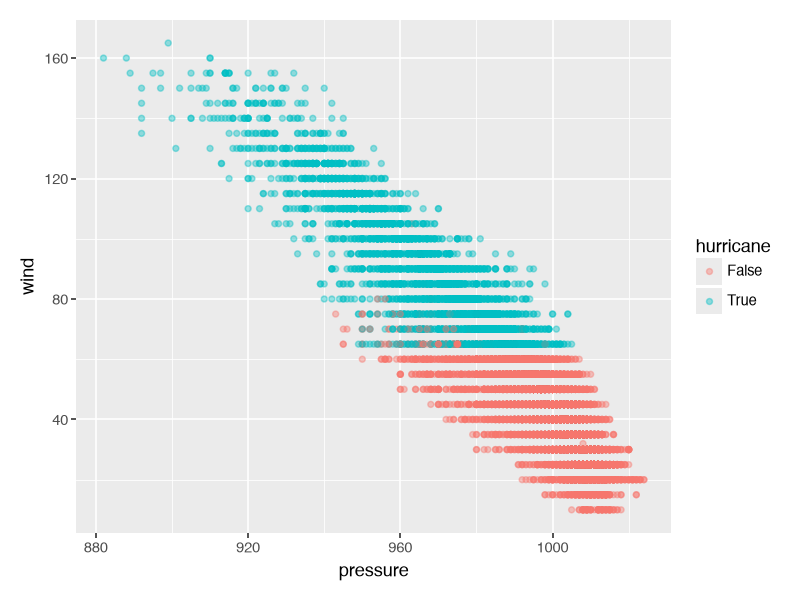

In [17]:
from plotnine import *

(
    ggplot(
        df_storms,
        aes(x="pressure", y="wind", color="hurricane")
    )
    + geom_point(alpha=0.4)
)

1. Inspect the scatterplot above. Suggest a simple classification rule that you suspect will have both high precision and high recall for the hurriance class based on the training data. **Without doing any coding, specify your rule and explain your reasoning.** This is NOT asking you to do nearest neighbors. Rather suggest a simple classification rule based on what you see in the plot.

**DISCUSS WITH YOUR PARTNER.**

2. For each of the following **compute the value and write a clearly worded sentence interpreting the value as a percentage in context.** Again, this is NOT asking you to fit a nearest neighbors model. You can write code, but you should only need to write basic code to make your predictions and get relevant counts from the training data. You can compute things like fractions by hand.

  a. training accuracy  
  b. training precision for the hurricane class  
  c. training recall for the hurricane class  
  d. training F1 score for the hurricane class  
  e. training precision for the non-hurricane class    
  f. training precision for the non-hurricane class  
  g. training F1 score for the non-hurricane class  

In [18]:
actual = df_storms["hurricane"]
predicted = df_storms["wind"] >= 64

tp = (predicted & actual).sum()
tn = (~predicted & ~actual).sum()
fp = (predicted & ~actual).sum()
fn = (~predicted & actual).sum()

accuracy = (tp + tn) / len(actual)
precision = tp / (tp + fp)
recall = tp / (tp + fn)
f1 = 2 * precision * recall / (precision + recall)

non_precision = tn / (tn + fn)
non_recall = tn / (tn + fp)
non_f1 = 2 * non_precision * non_recall / (non_precision + non_recall)

print(f"Accuracy: {accuracy:.1%} of storms were classified correctly.")
print(f"Hurricane precision: {precision:.1%} of predicted hurricanes were hurricanes.")
print(f"Hurricane recall: {recall:.1%} of hurricanes were identified.")
print(f"Hurricane F1: {f1:.1%}, combining hurricane precision and recall.")
print(f"Non-hurricane precision: {non_precision:.1%} of predicted non-hurricanes were non-hurricanes.")
print(f"Non-hurricane recall: {non_recall:.1%} of non-hurricanes were identified.")
print(f"Non-hurricane F1: {non_f1:.1%}, combining non-hurricane precision and recall.")

Accuracy: 99.3% of storms were classified correctly.
Hurricane precision: 97.3% of predicted hurricanes were hurricanes.
Hurricane recall: 100.0% of hurricanes were identified.
Hurricane F1: 98.7%, combining hurricane precision and recall.
Non-hurricane precision: 100.0% of predicted non-hurricanes were non-hurricanes.
Non-hurricane recall: 99.1% of non-hurricanes were identified.
Non-hurricane F1: 99.6%, combining non-hurricane precision and recall.


**DISCUSS WITH YOUR PARTNER.**

3. The "status" variable contains further breakdown of the non-hurricane class. Suppose we fit a **10-nearest neighbors** classification model for predicting status from wind speed and pressure. Without doing any coding, what status would the model predict for a storm with a pressure of 975 and wind speed of 39? **Explain your reasoning without doing any coding**. Hint: look at the scatterplot below, but be careful since some points are superimposed.

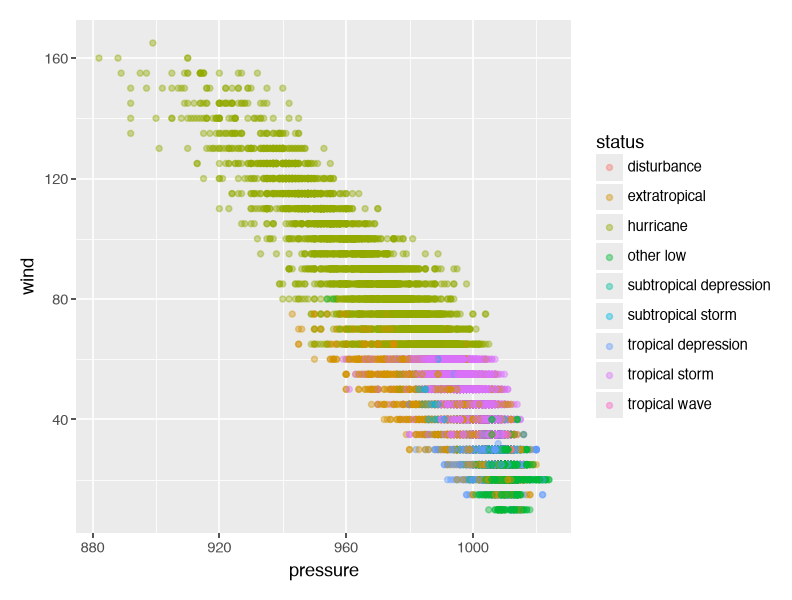

In [19]:
(
    ggplot(
        df_storms,
        aes(x="pressure", y="wind", color="status")
    )
    + geom_point(alpha=0.4)
)

**DISCUSS WITH YOUR PARTNER.**

4. Suppose we fit a **10-nearest neighbors** classification model for predicting status from wind speed and pressure. Without doing any coding, which classes do you think would have the lowest recall based on the training data? **Explain your reasoning without doing any coding.** Hint: look at the scatterplot above, but be careful since some points are superimposed.

**DISCUSS WITH YOUR PARTNER.**

## Practice Activity Titanic Data

We'll use $k$-nearest neighbors to predict who survives based on age, sex, and class.

In [20]:
df_titanic = pd.read_csv("https://dlsun.github.io/pods/data/titanic.csv ")

# drop the NaN for age since we're using it as a predictor
df_titanic = df_titanic.dropna(subset = ["age"])

df_titanic

,name,gender,age,class,embarked,country,ticketno,fare,survived
0,"Abbing, Mr. Anthony",male,42.0,3rd,S,United States,5547.0,7.11,0
1,"Abbott, Mr. Eugene Joseph",male,13.0,3rd,S,United States,2673.0,20.05,0
2,"Abbott, Mr. Rossmore Edward",male,16.0,3rd,S,United States,2673.0,20.05,0
3,"Abbott, Mrs. Rhoda Mary 'Rosa'",female,39.0,3rd,S,England,2673.0,20.05,1
4,"Abelseth, Miss. Karen Marie",female,16.0,3rd,S,Norway,348125.0,7.13,1
...,...,...,...,...,...,...,...,...,...
2202,"Wynn, Mr. Walter",male,41.0,deck crew,B,England,NaN,NaN,1
2203,"Yearsley, Mr. Harry",male,40.0,victualling crew,S,England,NaN,NaN,1
2204,"Young, Mr. Francis James",male,32.0,engineering crew,S,England,NaN,NaN,0
2205,"Zanetti, Sig. Minio",male,20.0,restaurant staff,S,England,NaN,NaN,0


1\. Train a 10-nearest neighbors model to predict whether or not a passenger on the Titanic survived, using their age, sex, and class as features.

In [21]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.metrics import PrecisionRecallDisplay
import matplotlib.pyplot as plt

X = df_titanic[["age", "gender", "class"]]
y = df_titanic["survived"]

preprocessor = ColumnTransformer([
    ("age", StandardScaler(), ["age"]),
    ("categories", OneHotEncoder(handle_unknown="ignore"), ["gender", "class"])
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("knn", KNeighborsClassifier(n_neighbors=10))
])

model.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('knn', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](3,)","['age','gender','class']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,3
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('age', ...), ('categories', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in 

In [22]:
df_titanic.columns.tolist()

['name',
 'gender',
 'age',
 'class',
 'embarked',
 'country',
 'ticketno',
 'fare',
 'survived']

2\. Use your model to predict whether a 20-year old female in first-class would survive. What about a 20-year old female in third-class? What are the predicted probabilities for each?

In [23]:
passengers = pd.DataFrame({
    "age": [20, 20],
    "gender": ["female", "female"],
    "class": ["1st", "3rd"]
})

results = passengers.copy()
results["predicted_survival"] = model.predict(passengers)
results["survival_probability"] = model.predict_proba(passengers)[:, 1]

results

,age,gender,class,predicted_survival,survival_probability
0,20,female,1st,1,1.0
1,20,female,3rd,0,0.2


3\. Calculate and interpret the training precision, recall, and F1 score for predicting survivors.

In [24]:
train_predictions = model.predict(X)

precision = precision_score(y, train_predictions, pos_label=1)
recall = recall_score(y, train_predictions, pos_label=1)
f1 = f1_score(y, train_predictions, pos_label=1)

print(f"Precision: {precision:.1%} of predicted survivors actually survived.")
print(f"Recall: {recall:.1%} of actual survivors were correctly identified.")
print(f"F1 score: {f1:.1%}, combining precision and recall for survivors.")

Precision: 85.0% of predicted survivors actually survived.
Recall: 53.3% of actual survivors were correctly identified.
F1 score: 65.5%, combining precision and recall for survivors.


4\. Calculate and interpret the training precision, recall, and F1 score for predicting non-survivors.

In [25]:
precision = precision_score(y, train_predictions, pos_label=0)
recall = recall_score(y, train_predictions, pos_label=0)
f1 = f1_score(y, train_predictions, pos_label=0)

print(f"Precision: {precision:.1%} of predicted non-survivors actually died.")
print(f"Recall: {recall:.1%} of actual non-survivors were correctly identified.")
print(f"F1 score: {f1:.1%}, combining precision and recall for non-survivors.")

Precision: 81.1% of predicted non-survivors actually died.
Recall: 95.5% of actual non-survivors were correctly identified.
F1 score: 87.7%, combining precision and recall for non-survivors.


5\. Since there are only two classes (survived or not) the model predicts survival if the predicted probability of survival is $0.5$ or higher. Change the threshold from 0.5 to 0.8 and compute the precision and recall for survivors and the non-survivors. How do the values compare to those with the threshold of 0.5?

In [26]:
survival_probability = model.predict_proba(X)[:, 1]

rows = []

for threshold in [0.5, 0.8]:
    predicted = (survival_probability >= threshold).astype(int)

    rows.append({
        "threshold": threshold,
        "survivor_precision": precision_score(y, predicted, pos_label=1),
        "survivor_recall": recall_score(y, predicted, pos_label=1),
        "non_survivor_precision": precision_score(y, predicted, pos_label=0),
        "non_survivor_recall": recall_score(y, predicted, pos_label=0)
    })

pd.DataFrame(rows).set_index("threshold")

,survivor_precision,survivor_recall,non_survivor_precision,non_survivor_recall
threshold,,,,
0.5,0.780531,0.620253,0.835366,0.917001
0.8,0.919003,0.414909,0.779193,0.982597


6\. Plot the precision-recall curve for the survivors. Interpret what you see.

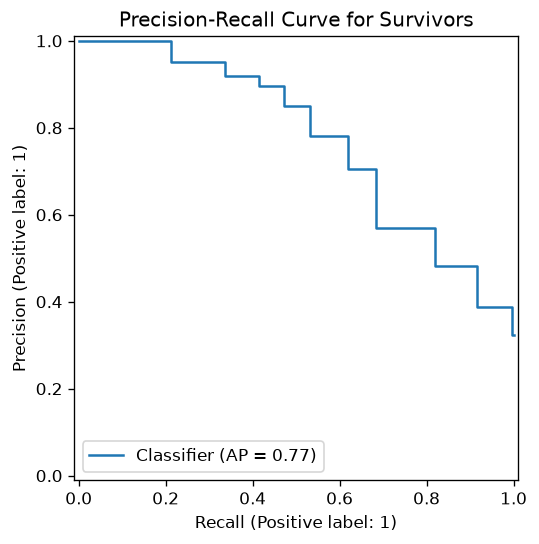

In [27]:
PrecisionRecallDisplay.from_predictions(
    y,
    survival_probability,
    pos_label=1
)

plt.title("Precision-Recall Curve for Survivors")
plt.show()

7\. Plot the precision-recall curve for non-survivors. Interpret what you see.

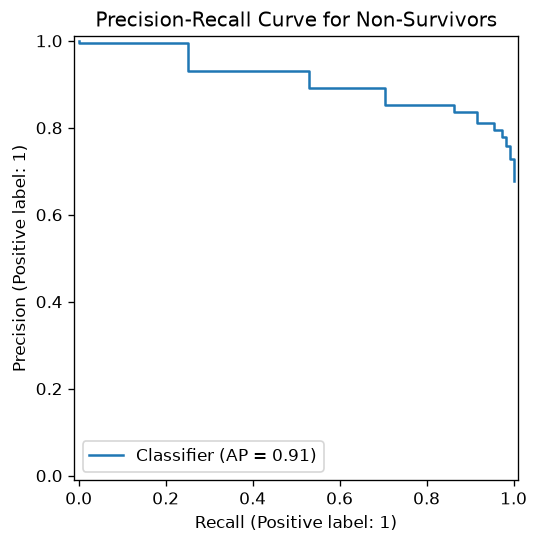

In [28]:
PrecisionRecallDisplay.from_predictions(
    y == 0,
    1 - survival_probability
)

plt.title("Precision-Recall Curve for Non-Survivors")
plt.show()